# 🔍 Lesson 3: Unsupervised Learning
**Week 5 · Notebook 3 of 10 · ⏱️ about 100 minutes**

---

## 🎯 Learning objectives
By the end of this lesson you will be able to:

1. **Explain** what unsupervised learning is and when it's useful.
2. **Cluster** data with K-Means, **choose** the number of clusters (elbow & silhouette), and **profile** the clusters it finds.
3. **Explain** why feature scaling is essential for distance-based algorithms.
4. **Discover patterns** beyond clustering: correlations and *association rules* (support, confidence, lift).
5. **Reduce dimensionality** with PCA, and decide how many components to keep.

## 🗺️ Roadmap
`Learning with no teacher` → `Clustering (K-Means, DBSCAN)` → `Pattern discovery` → `Dimensionality reduction (PCA)` → **Problems**

In [1]:
import sys
sys.path.append("..")
from course_utils import *
setup()

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.datasets import make_moons, load_digits

---
# 📖 Part 1: Learning with no teacher

In Lesson 2 every example came with an answer key. Now **we take the answer key away.** All we have is `X`; there is no `y`.

> 🧺 **Analogy:** someone dumps 400 unlabeled photographs on your desk and says *"organise these."* Nobody tells you the categories. You look, notice that some photos are of beaches, some of birthdays, some of cats, and you start making piles. **That's unsupervised learning**: finding structure that is already hidden in the data.

Why would anyone want this?

* **Labels are expensive**: unlabeled data is almost free.
* **We don't always know what to look for**: the algorithm may reveal groups we never imagined.
* **It's a great first step**: explore and understand data *before* supervised modelling.

The two great families we study:

| Family | Question it answers | Example |
|---|---|---|
| **Clustering** | *Which examples are similar to each other?* | customer segments, news topics |
| **Dimensionality reduction** | *Can I describe each example with fewer numbers?* | compress 64 pixels into 2 coordinates for plotting |

---
# 📖 Part 2: Clustering

A shopping mall has data on 400 customers. **Marketing wants customer segments** to design different promotions. Nobody has defined segments yet: a perfect clustering task.

In [2]:
customers = load("customers.csv")

# The file includes a hidden "segment_truth" column. In real life you would NEVER have this.
# We set it aside to "peek behind the curtain" at the very end, to see how well we did.
truth = customers["segment_truth"]
features = ["age", "annual_income_k", "spending_score", "visits_per_month"]
X = customers[features]

print(X.shape)
X.describe().loc[["mean", "std", "min", "max"]].round(1)

(400, 4)


,age,annual_income_k,spending_score,visits_per_month
mean,37.7,59.8,50.7,6.7
std,11.6,29.3,28.3,3.7
min,18.0,12.0,6.0,1.0
max,71.0,113.7,100.0,16.1


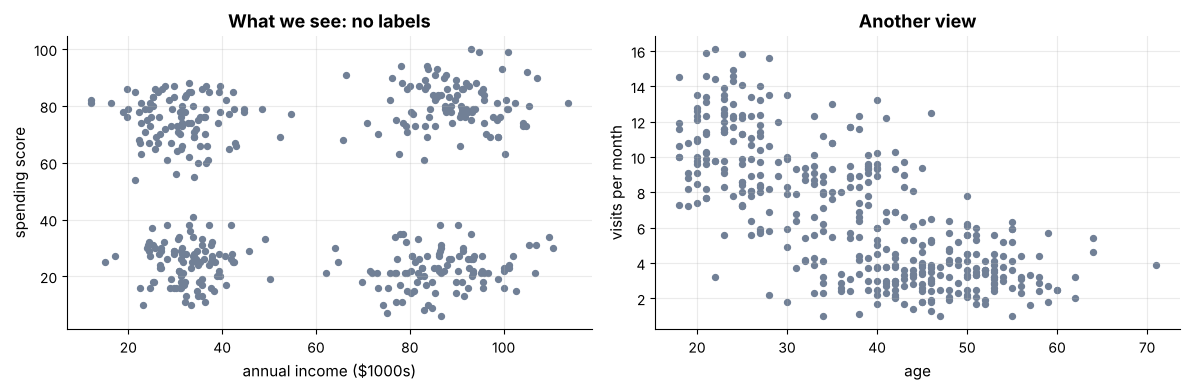

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(X["annual_income_k"], X["spending_score"], s=18, color=GREY)
axes[0].set_xlabel("annual income ($1000s)"); axes[0].set_ylabel("spending score"); axes[0].set_title("What we see: no labels")
axes[1].scatter(X["age"], X["visits_per_month"], s=18, color=GREY)
axes[1].set_xlabel("age"); axes[1].set_ylabel("visits per month"); axes[1].set_title("Another view")
plt.tight_layout(); plt.show()

Even without colours, your eye sees *blobs*. K-Means is the algorithm that finds them automatically.

## 2.1 K-Means: the algorithm in plain English

You choose the number of clusters **k**. Then:

1. **Initialise:** drop *k* "centres" (centroids) at random locations.
2. **Assign:** every point joins the cluster of its **nearest** centre.
3. **Update:** move each centre to the **average** of the points in its cluster.
4. **Repeat** steps 2–3 until nothing changes (convergence).

It's *"assign, then recentre, assign, then recentre…"* like people at a party drifting toward the nearest group, while each group's "middle" slowly relocates.

### 🧑‍🏫 Worked Example 1: K-Means by hand (1-D, k = 2)

Points: **1, 2, 4, 11, 12, 14.** Start with centres **c₁ = 1** and **c₂ = 4**. I'll do the arithmetic and let the code verify it.

* **Round 1: assign:** 1→c₁ (distance 0 vs 3) · 2→c₁ (1 vs 2) · 4→c₂ (3 vs 0) · 11, 12, 14→c₂. So clusters are {1, 2} and {4, 11, 12, 14}.
  **Update:** c₁ = (1+2)/2 = **1.5**; c₂ = (4+11+12+14)/4 = **10.25**.
* **Round 2: assign:** now 4 is 2.5 from c₁ but 6.25 from c₂ → 4 **switches** to c₁. Clusters {1, 2, 4} and {11, 12, 14}.
  **Update:** c₁ = 7/3 ≈ **2.33**; c₂ = 37/3 ≈ **12.33**.
* **Round 3: assign:** nobody moves → **converged**.

In [4]:
pts = np.array([1, 2, 4, 11, 12, 14], dtype=float)
centres = np.array([1.0, 4.0])

for round_no in range(1, 5):
    assignment = np.abs(pts[:, None] - centres[None, :]).argmin(axis=1)         # step 2: nearest centre
    new_centres = np.array([pts[assignment == j].mean() for j in range(2)])     # step 3: recentre
    print(f"Round {round_no}: clusters = {[list(pts[assignment==j]) for j in range(2)]}  ->  centres {new_centres.round(2)}")
    if np.allclose(new_centres, centres):
        print("   no change → converged!"); break
    centres = new_centres

Round 1: clusters = [[np.float64(1.0), np.float64(2.0)], [np.float64(4.0), np.float64(11.0), np.float64(12.0), np.float64(14.0)]]  ->  centres [ 1.5  10.25]


Round 2: clusters = [[np.float64(1.0), np.float64(2.0), np.float64(4.0)], [np.float64(11.0), np.float64(12.0), np.float64(14.0)]]  ->  centres [ 2.33 12.33]
Round 3: clusters = [[np.float64(1.0), np.float64(2.0), np.float64(4.0)], [np.float64(11.0), np.float64(12.0), np.float64(14.0)]]  ->  centres [ 2.33 12.33]
   no change → converged!


My hand calculation matches. Now let's run it on the real customers, but first, a crucial detail.

## 2.2 Why you must scale features for distance-based algorithms

K-Means decides by **distance**. Suppose income were recorded in **dollars** (85,000) while age is in **years** (45). The distance between two customers would be dominated by income: age would be a rounding error. Let me *prove* that using the hidden truth to score each attempt (1.0 = perfect agreement, 0 = random):

In [5]:
X_dollars = X.copy()
X_dollars["annual_income_k"] = X_dollars["annual_income_k"] * 1000     # income now in dollars

scaled = StandardScaler().fit_transform(X)            # mean 0, std 1 for every column
scaled_dollars = StandardScaler().fit_transform(X_dollars)

def kmeans_score(data, k=4):
    labels = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(data)
    return adjusted_rand_score(truth, labels)

print(f"Raw features, income in $1000s : agreement with truth = {kmeans_score(X):.2f}")
print(f"Raw features, income in dollars: agreement with truth = {kmeans_score(X_dollars):.2f}   <- income swamps everything")
print(f"Scaled features (any units)    : agreement with truth = {kmeans_score(scaled_dollars):.2f}   <- units no longer matter")

Raw features, income in $1000s : agreement with truth = 0.99
Raw features, income in dollars: agreement with truth = 0.34   <- income swamps everything
Scaled features (any units)    : agreement with truth = 0.99   <- units no longer matter


**Standardisation** (`StandardScaler`) rewrites each column as *"how many standard deviations from the mean"*: `z = (x − mean) / std`. After that, every feature speaks the same language, and changing units no longer changes the answer.

> 📏 **Rule:** scale before any algorithm that uses distances (K-Means, KNN, SVM) or penalties/gradients (regularised and gradient-descent models; Lessons 5 & 8).

## 2.3 Running K-Means, and choosing *k*

In [6]:
Xs = StandardScaler().fit_transform(X)

km = KMeans(n_clusters=4, n_init=10, random_state=0).fit(Xs)
customers["cluster"] = km.labels_
print("cluster sizes:", np.bincount(km.labels_))
print("inertia (total squared distance to centres):", round(km.inertia_, 1))

cluster sizes: [100 101  99 100]
inertia (total squared distance to centres): 268.7


But how did I know to ask for 4 clusters? **I didn't**: *k* is a hyperparameter, and choosing it is the central practical difficulty of clustering. Two standard tools:

* **Elbow method.** *Inertia* = total squared distance from each point to its centre. It always shrinks as *k* grows (with *k* = n every point is its own cluster: inertia 0!). Look for the **elbow**, where improvements become small.
* **Silhouette score.** For each point: `s = (b − a) / max(a, b)`, where *a* = average distance to its *own* cluster, *b* = average distance to the *nearest other* cluster. Ranges from −1 to +1; **higher is better**. Average it over all points.

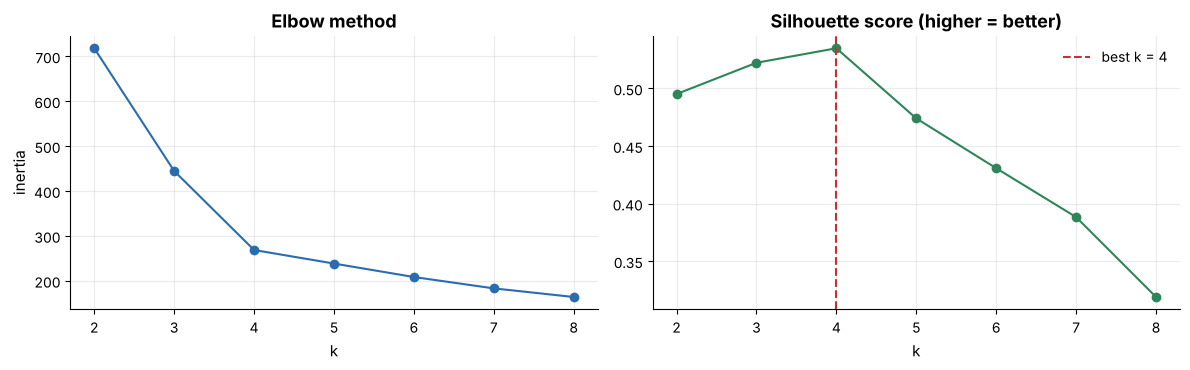

In [7]:
ks = range(2, 9)
inertias, sils = [], []
for k in ks:
    m = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Xs)
    inertias.append(m.inertia_)
    sils.append(silhouette_score(Xs, m.labels_))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(list(ks), inertias, "o-", color=BLUE); axes[0].set_title("Elbow method"); axes[0].set_xlabel("k"); axes[0].set_ylabel("inertia")
axes[1].plot(list(ks), sils, "o-", color=GREEN); axes[1].set_title("Silhouette score (higher = better)"); axes[1].set_xlabel("k")
best_k_demo = list(ks)[int(np.argmax(sils))]
axes[1].axvline(best_k_demo, color=RED, ls="--", label=f"best k = {best_k_demo}"); axes[1].legend()
plt.tight_layout(); plt.show()

Both plots agree: the elbow bends sharply at **k = 4**, and the silhouette peaks there too. (Real data is rarely this tidy; when the two disagree, use domain knowledge: *how many segments can marketing actually act on?*)

## 2.4 Profiling the clusters: turning numbers into insight

An algorithm gives you cluster *ids* (0, 1, 2, 3). **Your job as a data scientist is to explain what each cluster means.** The classic trick: average each feature per cluster.

In [8]:
profile = customers.groupby("cluster")[features].mean().round(1)
profile["size"] = customers["cluster"].value_counts().sort_index()
profile

,age,annual_income_k,spending_score,visits_per_month,size
cluster,,,,,
0,47.6,86.6,22.3,3.0,100
1,23.1,31.1,75.0,11.0,101
2,34.8,89.6,80.7,8.6,99
3,45.6,32.7,24.7,4.2,100


Read the table like a marketer:

* A cluster with **high income, high spending, many visits** → "VIP shoppers".
* **High income, low spending, few visits** → "wealthy savers" (opportunity: why don't they spend?).
* **Low income, high spending, young, frequent visits** → "trendy youth".
* **Low income, low spending** → "budget-conscious".

Naming the clusters is where unsupervised learning creates *business value*.

### 🕵️ Peek behind the curtain
Now we check against the hidden truth. (Remember: in real life, you can't.)

In [9]:
print("Agreement with the hidden segments (adjusted Rand index):", round(adjusted_rand_score(truth, customers["cluster"]), 3))
pd.crosstab(customers["segment_truth"], customers["cluster"], rownames=["true segment"], colnames=["found cluster"])

Agreement with the hidden segments (adjusted Rand index): 0.993


found cluster,0,1,2,3
true segment,,,,
0,100,0,0,0
1,0,1,99,0
2,0,100,0,0
3,0,0,0,100


Each true segment maps almost entirely into **one** found cluster (the numbering is arbitrary; cluster 2 here might be segment 0 there). K-Means rediscovered the hidden structure without ever being told it existed. 🎉

## 2.5 When K-Means fails: and an alternative

K-Means assumes clusters are **round blobs of similar size**. Real data isn't always so polite. **DBSCAN** groups points by *density* ("a cluster is a crowd; loners are noise") and doesn't need *k*, but needs a neighbourhood radius `eps` instead.

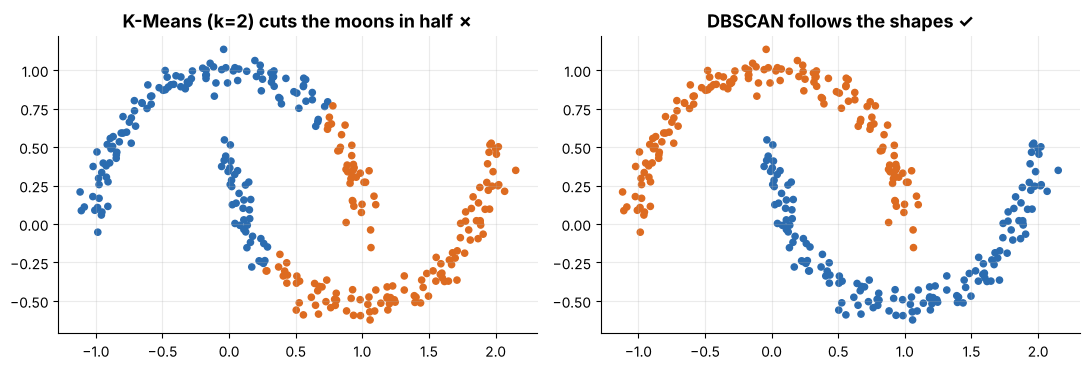

In [10]:
moons, _ = make_moons(n_samples=300, noise=0.06, random_state=0)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, labels, title in [(axes[0], KMeans(2, n_init=10, random_state=0).fit_predict(moons), "K-Means (k=2) cuts the moons in half ✗"),
                          (axes[1], DBSCAN(eps=0.2, min_samples=5).fit_predict(moons), "DBSCAN follows the shapes ✓")]:
    ax.scatter(*moons.T, c=[PALETTE[l % 6] for l in labels], s=20); ax.set_title(title)
plt.tight_layout(); plt.show()

**Takeaway:** there is no universally best clustering algorithm. Look at your data, understand each algorithm's assumptions, and always *validate* by profiling the result.

---
# 📖 Part 3: Pattern discovery

Clustering groups *rows*. Pattern discovery asks other questions: *which columns move together? which items are bought together?*

## 3.1 Correlation structure

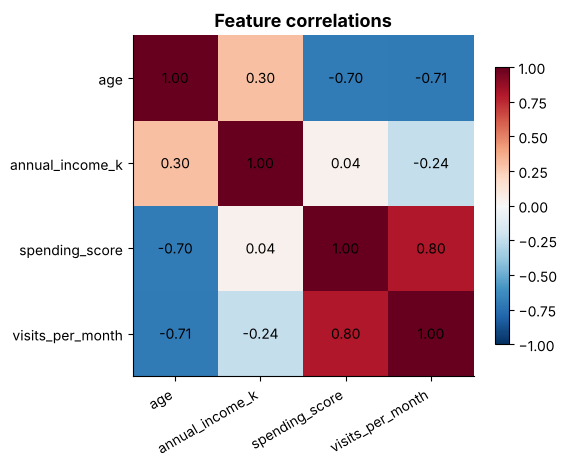

In [11]:
corr = X.corr()
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(4)); ax.set_xticklabels(features, rotation=30, ha="right")
ax.set_yticks(range(4)); ax.set_yticklabels(features); ax.grid(False)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=10)
plt.colorbar(im, shrink=0.8); ax.set_title("Feature correlations"); plt.show()

Strongly correlated features carry **redundant** information: a hint that fewer dimensions might describe the data nearly as well (that's PCA, coming up).

## 3.2 Association rules: "people who buy X also buy Y"

A supermarket logs shopping baskets. Three numbers describe a rule *A → B* ("if bread, then butter"):

| Measure | Formula | Meaning |
|---|---|---|
| **Support**(A, B) | (baskets containing A **and** B) ÷ (all baskets) | how common is the combo? |
| **Confidence**(A → B) | support(A, B) ÷ support(A) | given A, how often is B also there? |
| **Lift**(A → B) | confidence(A → B) ÷ support(B) | is B *more* likely than usual when A is present? `>1` yes · `1` independent · `<1` less |

### 🧑‍🏫 Worked Example 2: Diapers and beer
Five baskets. Does buying **diapers** make **beer** more likely?

In [12]:
baskets = [{"bread", "milk"},
           {"bread", "diapers", "beer", "eggs"},
           {"milk", "diapers", "beer", "cola"},
           {"bread", "milk", "diapers", "beer"},
           {"bread", "milk", "diapers", "cola"}]

def support(items):
    items = set(items)
    return sum(items <= basket for basket in baskets) / len(baskets)

s_both, s_diapers, s_beer = support({"diapers", "beer"}), support({"diapers"}), support({"beer"})
confidence = s_both / s_diapers
lift = confidence / s_beer

print(f"support(diapers, beer)    = {s_both:.2f}   (3 of 5 baskets)")
print(f"confidence(diapers→beer)  = {confidence:.2f}   (3 of the 4 diaper baskets also hold beer)")
print(f"lift(diapers→beer)        = {lift:.2f}   (beer is {lift:.2f}× more likely when diapers are present)")

support(diapers, beer)    = 0.60   (3 of 5 baskets)
confidence(diapers→beer)  = 0.75   (3 of the 4 diaper baskets also hold beer)
lift(diapers→beer)        = 1.25   (beer is 1.25× more likely when diapers are present)


Lift 1.25 > 1 → buying diapers *does* raise the chance of beer. (With only five baskets, don't bet the store on it, which is why real systems demand large support.) The ***Apriori*** algorithm scales this idea to millions of baskets by only exploring item combinations that are already frequent.

---
# 📖 Part 4: Dimensionality reduction with PCA

Our digits dataset has **64 features per image** (an 8×8 grid of pixel intensities). We can't plot 64 dimensions. **Principal Component Analysis (PCA)** finds a *new set of axes* (ordered by how much variation they capture) so we can keep the first few and drop the rest.

> 📸 **Analogy:** a 3-D object casts a 2-D shadow. Rotate the object so the shadow is as *informative* as possible and you've done PCA.

**Principal components** are directions in the data:
* **PC1**: the direction of **maximum variance**.
* **PC2**: the direction of maximum variance *perpendicular to PC1*, and so on.

### 🧑‍🏫 Worked Example 3: PCA in two dimensions, from scratch
PCA is *eigen-decomposition of the covariance matrix.* Here's every step on 2-D correlated data so we can *see* it:

variance along PC1, PC2   : [6.2 0.4]
share of variance (PC1,PC2): [0.939 0.061]

sklearn explained_variance_ratio_: [0.939 0.061]   ← same numbers


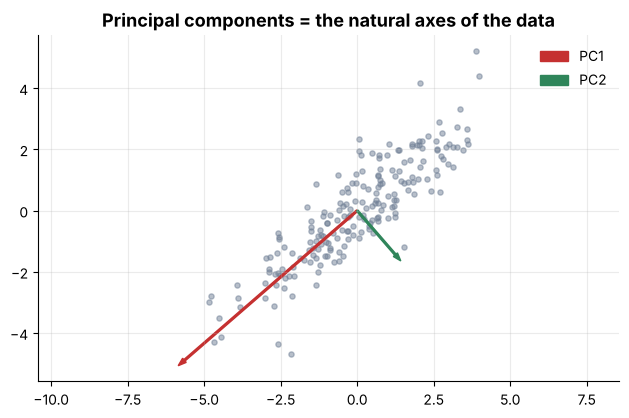

In [13]:
rng = np.random.default_rng(0)
a = rng.normal(0, 2, 200)
data = np.c_[a, 0.8 * a + rng.normal(0, 0.8, 200)]
data = data - data.mean(axis=0)                      # step 1: centre the data

cov = np.cov(data.T)                                 # step 2: covariance matrix
eigvals, eigvecs = np.linalg.eigh(cov)               # step 3: eigenvectors = principal directions
order = eigvals.argsort()[::-1]                      #         sort by variance, largest first
eigvals, eigvecs = eigvals[order], eigvecs[:, order]

print("variance along PC1, PC2   :", eigvals.round(2))
print("share of variance (PC1,PC2):", (eigvals / eigvals.sum()).round(3))

sk = PCA(n_components=2).fit(data)                   # compare with scikit-learn
print("\nsklearn explained_variance_ratio_:", sk.explained_variance_ratio_.round(3), "  ← same numbers")

plt.scatter(*data.T, s=14, alpha=0.5, color=GREY)
for i, c in enumerate([RED, GREEN]):
    plt.arrow(0, 0, *(eigvecs[:, i] * 3 * np.sqrt(eigvals[i])), color=c, width=0.06, label=f"PC{i+1}")
plt.axis("equal"); plt.legend(); plt.title("Principal components = the natural axes of the data")
plt.show()

PC1 (red) runs along the long axis of the cloud and captures ~94% of the variation; PC2 captures the remaining sliver. **If we threw PC2 away we'd lose almost nothing**: 2 numbers per point become 1.

### PCA on handwritten digits: 64 → 2
We don't use the digit labels for PCA, but we'll *colour by them afterwards* to check that the 2-D picture is meaningful.

each image has 64 pixel features


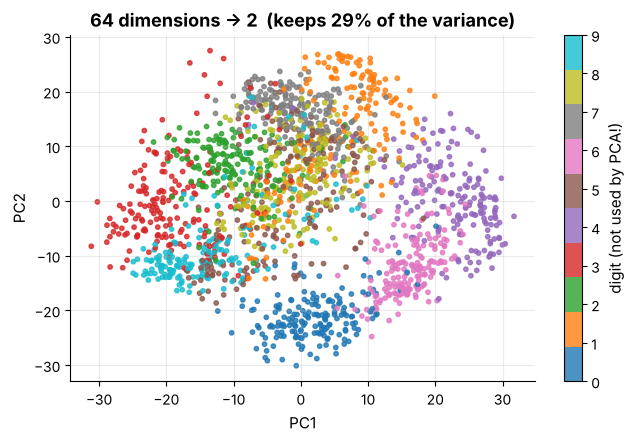

In [14]:
digits = load_digits()
Xd, yd = digits.data, digits.target
print("each image has", Xd.shape[1], "pixel features")

pca2 = PCA(n_components=2).fit(Xd)
Z = pca2.transform(Xd)
sc = plt.scatter(Z[:, 0], Z[:, 1], c=yd, cmap="tab10", s=10, alpha=0.8)
plt.colorbar(sc, label="digit (not used by PCA!)")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title(f"64 dimensions → 2  (keeps {pca2.explained_variance_ratio_.sum():.0%} of the variance)")
plt.show()

With only 2 numbers per image, digits already form visible neighbourhoods, and no label was used! But two components keep only ~29% of the information. How many do we *really* need? Plot the **cumulative explained variance**:

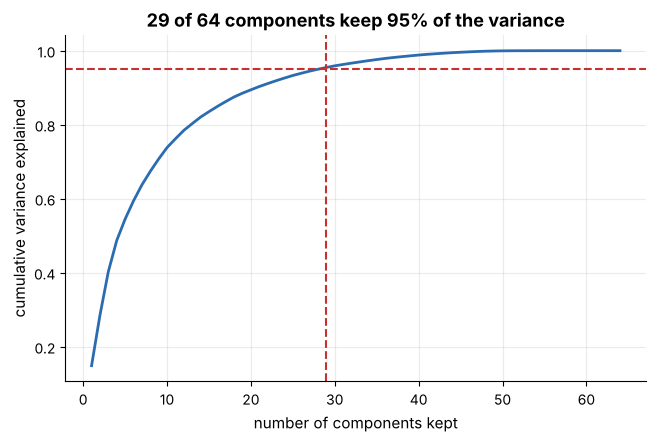

In [15]:
full = PCA().fit(Xd)
cum = np.cumsum(full.explained_variance_ratio_)
n95 = int(np.argmax(cum >= 0.95)) + 1

plt.plot(range(1, 65), cum, color=BLUE, lw=2)
plt.axhline(0.95, color=RED, ls="--"); plt.axvline(n95, color=RED, ls="--")
plt.xlabel("number of components kept"); plt.ylabel("cumulative variance explained")
plt.title(f"{n95} of 64 components keep 95% of the variance")
plt.show()

### What does "keeping variance" look like? Reconstruct the images
Compress each image to *n* numbers, then rebuild the picture from them:

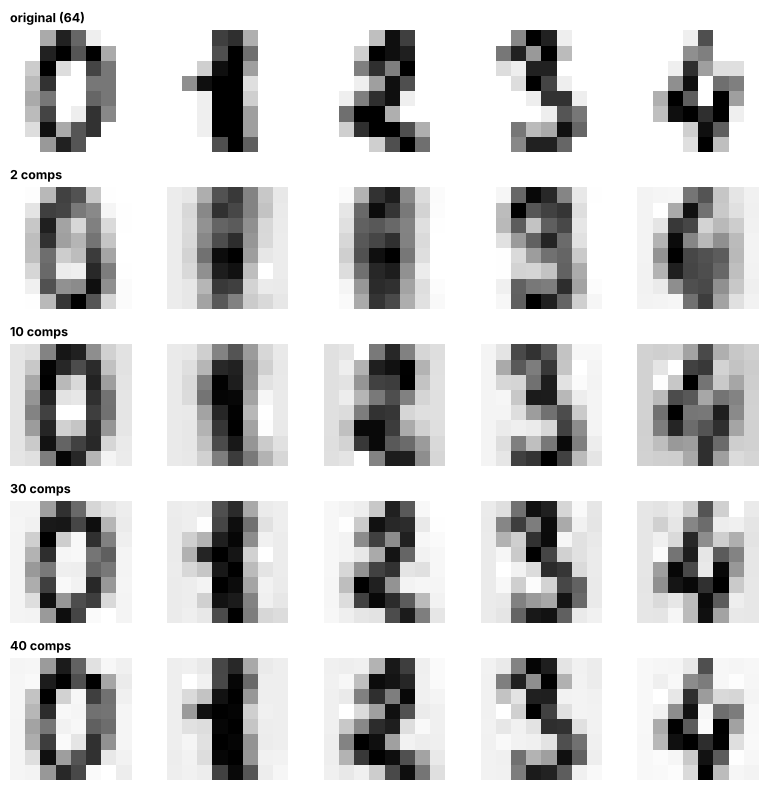

In [16]:
fig, axes = plt.subplots(5, 5, figsize=(8, 8))
for row, n in enumerate([None, 2, 10, 30, 40]):
    if n is None:
        recon = Xd[:5]; label = "original (64)"
    else:
        p = PCA(n_components=n).fit(Xd)
        recon = p.inverse_transform(p.transform(Xd[:5])); label = f"{n} comps"
    for col in range(5):
        axes[row, col].imshow(recon[col].reshape(8, 8), cmap="gray_r"); axes[row, col].axis("off")
    axes[row, 0].set_title(label, fontsize=9, loc="left")
plt.tight_layout(); plt.show()

With **2** components the digits are blurry blobs; with **10** you can read most of them; with **~30–40** they're nearly indistinguishable from the originals. That is **lossy compression**, and PCA tells you exactly how much you're trading away.

> 🔧 **When to use PCA:** visualisation, noise reduction, speeding up models, and removing redundant correlated features. **Caveats:** PCA components are *linear mixtures* of features, so they're harder to interpret; and always standardise first if features have different units.

---
# 🧩 Your turn: Problems

### 🧩 Problem 3.1: Segment the customers &nbsp; ⭐

1. Load `customers.csv` and use the four features `["age", "annual_income_k", "spending_score", "visits_per_month"]` (ignore `segment_truth`).
2. **Standardise** them with `StandardScaler`.
3. Fit `KMeans(n_clusters=4, n_init=10, random_state=0)`.
4. Store the cluster label of every customer in `labels`.

**Stuck?** Open the hints one at a time: try again between each one.

<details>
<summary>💡 Hint 1</summary>

`StandardScaler().fit_transform(X)` returns the scaled array.

</details>

<details>
<summary>💡 Hint 2</summary>

After `fit`, the labels are in `km.labels_` (or use `fit_predict`).

</details>

In [ ]:
customers = load("customers.csv")
features = ["age", "annual_income_k", "spending_score", "visits_per_month"]

labels = None
print(labels)

In [ ]:
# ✔ Self-check - run this after you have solved the problem
truth = load("customers.csv")["segment_truth"]
check("one label per customer", lambda: len(labels) == 400)
check("exactly 4 clusters", lambda: len(set(labels)) == 4)
check("clusters match the hidden segments well (ARI > 0.9)", lambda: adjusted_rand_score(truth, labels) > 0.9)

### 🧩 Problem 3.2: Choose k with the silhouette score &nbsp; ⭐⭐

For every `k` from **2 to 8**, fit K-Means on the **standardised** customer features (use `n_init=10, random_state=0`) and compute the silhouette score.

Store the scores in a dictionary `sil_scores` (`{k: score}`) and the *k* with the highest score in `best_k`.

**Stuck?** Open the hints one at a time: try again between each one.

<details>
<summary>💡 Hint 1</summary>

Loop `for k in range(2, 9):`, fit `KMeans(n_clusters=k, ...)`, and call `silhouette_score(Xs, model.labels_)`.

</details>

<details>
<summary>💡 Hint 2</summary>

`max(sil_scores, key=sil_scores.get)` returns the dictionary key with the largest value.

</details>

In [ ]:
customers = load("customers.csv")
Xs = StandardScaler().fit_transform(customers[["age", "annual_income_k", "spending_score", "visits_per_month"]])

sil_scores = {}
best_k = None
print(best_k)

In [ ]:
# ✔ Self-check - run this after you have solved the problem
check("scores for k = 2..8", lambda: sorted(sil_scores) == list(range(2, 9)))
check("every score is between -1 and 1", lambda: all(-1 <= v <= 1 for v in sil_scores.values()))
check("best_k is the k with the max score", lambda: best_k == max(sil_scores, key=sil_scores.get))
check("best_k = 4 (the real number of segments)", lambda: best_k == 4)

### 🧩 Problem 3.3: Name the segments (cluster profiling) &nbsp; ⭐⭐

Using your 4-cluster K-Means on the standardised customers:

1. Create a DataFrame `profile` with the **mean `annual_income_k` and mean `spending_score` of each cluster** (index = cluster id).
2. Store in `vip_cluster` the **id** of the cluster with the highest *average spending score among clusters whose average income is above 70*.

**Stuck?** Open the hints one at a time: try again between each one.

<details>
<summary>💡 Hint 1</summary>

Add the labels as a column, then `df.groupby("cluster")[["annual_income_k", "spending_score"]].mean()`.

</details>

<details>
<summary>💡 Hint 2</summary>

Filter with `profile[profile["annual_income_k"] > 70]`, then take `.idxmax()` of the spending column.

</details>

In [ ]:
customers = load("customers.csv")
Xs = StandardScaler().fit_transform(customers[["age", "annual_income_k", "spending_score", "visits_per_month"]])
customers["cluster"] = KMeans(n_clusters=4, n_init=10, random_state=0).fit_predict(Xs)

profile = None
vip_cluster = None
print(profile); print(vip_cluster)

In [ ]:
# ✔ Self-check - run this after you have solved the problem
check("profile has 4 rows and the 2 requested columns", lambda: profile.shape == (4, 2))
check("vip cluster has high income (> 70)", lambda: profile.loc[vip_cluster, "annual_income_k"] > 70)
check("vip cluster has high spending (> 65)", lambda: profile.loc[vip_cluster, "spending_score"] > 65)

### 🧩 Problem 3.4: How many components? (PCA on wine) &nbsp; ⭐⭐

Load `wine.csv` (178 wines, 13 chemical measurements; the `target` column is the grape variety; *do not use it as a feature*).

1. Standardise the 13 features.
2. Fit a full `PCA()`.
3. Store `var_first_two`, the fraction of variance explained by the **first two** components, and `n_90`, the **smallest number of components** whose cumulative explained variance is **at least 90%**.

**Stuck?** Open the hints one at a time: try again between each one.

<details>
<summary>💡 Hint 1</summary>

`pca.explained_variance_ratio_` gives the share per component; `np.cumsum(...)` accumulates them.

</details>

<details>
<summary>💡 Hint 2</summary>

`int(np.argmax(cum >= 0.90)) + 1` finds the first position where the cumulative curve reaches 0.90 (and +1 turns an index into a count).

</details>

In [ ]:
wine = load("wine.csv")
X_wine = wine.drop(columns="target")

var_first_two = None
n_90 = None
print(var_first_two, n_90)

In [ ]:
# ✔ Self-check - run this after you have solved the problem
_r = PCA().fit(StandardScaler().fit_transform(load("wine.csv").drop(columns="target"))).explained_variance_ratio_
check("variance of first two PCs is about 55%", lambda: abs(var_first_two - _r[:2].sum()) < 1e-6)
check("n_90 is correct", lambda: n_90 == int(np.argmax(np.cumsum(_r) >= 0.90)) + 1)
check("n_90 is smaller than the 13 original features", lambda: n_90 < 13)

### 🧩 Problem 3.5: Market-basket analysis &nbsp; ⭐⭐

Ten shoppers' baskets are given below. Compute for the rule **milk → bread**:

* `sup_both`: the support of {milk, bread}
* `conf`: the confidence of milk → bread
* `lift`: the lift of milk → bread

Then decide: does buying milk really make bread *more* likely? Store `True`/`False` in `milk_boosts_bread`.

**Stuck?** Open the hints one at a time: try again between each one.

<details>
<summary>💡 Hint 1</summary>

Count baskets where `{"milk","bread"} <= basket` (set-inclusion). Divide by 10 for support.

</details>

<details>
<summary>💡 Hint 2</summary>

`conf = support(milk and bread) / support(milk)`;  `lift = conf / support(bread)`. A lift very close to 1 means "no real boost".

</details>

In [ ]:
baskets = [{"milk", "bread", "eggs"}, {"milk", "bread"}, {"bread", "butter"}, {"milk", "eggs"},
           {"milk", "bread", "butter"}, {"bread", "eggs"}, {"milk", "bread", "eggs", "butter"},
           {"eggs"}, {"milk", "bread"}, {"bread", "butter"}]

sup_both = conf = lift = None
milk_boosts_bread = None
print(sup_both, conf, lift, milk_boosts_bread)

In [ ]:
# ✔ Self-check - run this after you have solved the problem
check("support of {milk, bread} = 0.5", lambda: abs(sup_both - 0.5) < 1e-9)
check("confidence = 5/6", lambda: abs(conf - 5 / 6) < 1e-9)
check("lift = (5/6)/0.8", lambda: abs(lift - (5 / 6) / 0.8) < 1e-9)
check("verdict: only a tiny boost (lift < 1.1) → False", lambda: milk_boosts_bread is False)

### 🧩 Problem 3.6: K-Means from scratch &nbsp; ⭐⭐⭐

Implement `my_kmeans(X, k, n_iter=100, n_init=10, seed=0)` using **only NumPy**. It should return `(labels, centres)`.

* Initialise centres by picking `k` random data points.
* Repeat *assign → update* until the centres stop moving (or `n_iter` rounds).
* Run `n_init` times from different random starts and keep the run with the lowest **inertia** (sum of squared distances to the assigned centre).

*(Edge case: if a cluster becomes empty, keep its old centre.)*

**Stuck?** Open the hints one at a time: try again between each one.

<details>
<summary>💡 Hint 1</summary>

Distances from every point to every centre in one go: `((X[:, None, :] - centres[None, :, :]) ** 2).sum(axis=2)` has shape `(n_points, k)`.

</details>

<details>
<summary>💡 Hint 2</summary>

`labels = dists.argmin(axis=1)`; new centre *j* = `X[labels == j].mean(axis=0)`.

</details>

<details>
<summary>💡 Hint 3</summary>

Wrap the loop in `for init in range(n_init)` with `rng = np.random.default_rng(seed + init)` and keep the best (lowest inertia) result.

</details>

In [ ]:
def my_kmeans(X, k, n_iter=100, n_init=10, seed=0):
    # your code here
    labels, centres = None, None
    return labels, centres

In [ ]:
# ✔ Self-check - run this after you have solved the problem
_c = load("customers.csv")
_X = StandardScaler().fit_transform(_c[["age", "annual_income_k", "spending_score", "visits_per_month"]])
_labels, _centres = my_kmeans(_X, 4)
check("returns 400 labels and 4 centres", lambda: len(_labels) == 400 and _centres.shape == (4, 4))
check("recovers the hidden segments (ARI > 0.9)", lambda: adjusted_rand_score(_c["segment_truth"], _labels) > 0.9)

---
## 🎟️ Exit ticket

**Q1.** What is the key difference between supervised and unsupervised learning?
**Q2.** Why must you standardise features before K-Means?
**Q3.** Two clusterings of the same data have silhouette 0.31 and 0.58. Which is better, and what does the silhouette measure?
**Q4.** A rule has confidence 90% but lift 1.0. Is it useful?
**Q5.** PCA on 50 features shows 3 components explain 97% of variance. What can you conclude, and what's the catch?

<details><summary>👀 Answers</summary>

**A1.** Unsupervised data has no labels (no `y`); the goal is to find structure rather than predict a known answer.
**A2.** K-Means uses distances; features with larger numeric ranges would dominate. Scaling puts all features on equal footing.
**A3.** 0.58 is better. The silhouette compares each point's distance to its own cluster versus the nearest other cluster (−1 to +1, higher = tighter, better-separated clusters).
**A4.** Not by itself: lift 1.0 means the consequent is no more likely when the antecedent is present: the "90%" is just how common the item is overall.
**A5.** The 50 features are highly redundant; 3 numbers per sample capture almost everything. The catch: components are mixtures of the originals, so they're harder to explain.

</details>

---
## 📌 Recap: Lesson 3 on one page

* **Unsupervised learning** discovers structure with no labels: **clustering** (group rows) and **dimensionality reduction** (compress columns).
* **K-Means:** *initialise → assign → update → repeat*. Needs *k* (a hyperparameter): use **elbow** and **silhouette**, then **profile** clusters (`groupby().mean()`) to name them.
* **Scale features** before any distance-based method (`StandardScaler`: z = (x − mean)/std).
* K-Means likes round blobs; **DBSCAN** handles arbitrary shapes and noise.
* **Pattern discovery:** correlations; association rules → *support, confidence, lift* (lift is the honest one).
* **PCA** rotates data onto axes of maximum variance; keep enough components for, say, 90–95% of the variance; **standardise first**.

**Next up →** `04_model_training.ipynb`: how to train a supervised model *honestly* with train / validation / test splits.